#   0. Importar Librerias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Cargar el Dataset
df = pd.read_csv("adult.csv")

El Adult Income Dataset es uno de los conjuntos de datos más populares de Machine Learning, extraído del censo de 1994 de EE. UU.
El objetivo es Predecir si una persona gana más o menos de $50,000 USD al año.
32k registros y 14 atributos.

#   1. Conocer el Dataset

In [3]:
df.head(4)

,Unnamed: 0,age,workclass,education,education-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,0,39,State-gov,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174.0,0.0,40,United-States,<=50K
1,1,50,Self-emp-not-inc,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,13,United-States,<=50K
2,2,38,Private,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.0,0.0,40,United-States,<=50K
3,3,53,Private,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,NaN,NaN,40,United-States,<=50K


In [4]:
df.tail()

,Unnamed: 0,age,workclass,education,education-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
32557,32557,40,Private,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0.0,0.0,40,United-States,>50K
32558,32558,58,Private,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0.0,0.0,40,United-States,<=50K
32559,32559,22,Private,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0.0,0.0,20,United-States,<=50K
32560,32560,52,Self-emp-inc,HS-grad,9,Married-civ-spouse,Exec-managerial,Wife,White,Female,15024.0,0.0,40,United-States,>50K
32561,32560,52,Self-emp-inc,HS-grad,9,Married-civ-spouse,Exec-managerial,Wife,White,Female,15024.0,0.0,40,United-States,>50K


In [5]:
df.shape

(32562, 15)

In [6]:
df.sample(6)

,Unnamed: 0,age,workclass,education,education-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
21337,21337,40,Local-gov,Masters,14,Divorced,Prof-specialty,Unmarried,White,Female,0.0,0.0,44,United-States,<=50K
32252,32252,37,Self-emp-not-inc,Bachelors,13,Married-civ-spouse,Sales,Wife,White,Female,0.0,0.0,50,United-States,<=50K
26052,26052,19,Private,HS-grad,9,Never-married,Handlers-cleaners,Own-child,White,Male,0.0,0.0,25,United-States,<=50K
22688,22688,49,Private,Assoc-voc,11,Married-civ-spouse,Craft-repair,Husband,White,Male,5013.0,0.0,40,United-States,<=50K
27895,27895,21,Private,Some-college,10,Never-married,Sales,Own-child,White,Female,0.0,0.0,47,United-States,<=50K
17631,17631,35,Private,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,0.0,0.0,55,United-States,<=50K


In [7]:
df.columns

Index(['Unnamed: 0', 'age', 'workclass', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'gender',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='object')

#   2. Tipo de Variable

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32562 entries, 0 to 32561
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      32562 non-null  int64  
 1   age             32562 non-null  int64  
 2   workclass       32562 non-null  object 
 3   education       32562 non-null  object 
 4   education-num   32562 non-null  int64  
 5   marital-status  32562 non-null  object 
 6   occupation      32562 non-null  object 
 7   relationship    32562 non-null  object 
 8   race            32562 non-null  object 
 9   gender          32562 non-null  object 
 10  capital-gain    32561 non-null  float64
 11  capital-loss    32561 non-null  float64
 12  hours-per-week  32562 non-null  int64  
 13  native-country  32562 non-null  object 
 14  income          32562 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 3.7+ MB


In [9]:
df.dtypes

,0
Unnamed: 0,int64
age,int64
workclass,object
education,object
education-num,int64
marital-status,object
occupation,object
relationship,object
race,object
gender,object


In [10]:
df.select_dtypes(include="object")

,workclass,education,marital-status,occupation,relationship,race,gender,native-country,income
0,State-gov,Bachelors,Never-married,Adm-clerical,Not-in-family,White,Male,United-States,<=50K
1,Self-emp-not-inc,Bachelors,Married-civ-spouse,Exec-managerial,Husband,White,Male,United-States,<=50K
2,Private,HS-grad,Divorced,Handlers-cleaners,Not-in-family,White,Male,United-States,<=50K
3,Private,11th,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,United-States,<=50K
4,Private,Bachelors,Married-civ-spouse,Prof-specialty,Wife,Black,Female,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...
32557,Private,HS-grad,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,United-States,>50K
32558,Private,HS-grad,Widowed,Adm-clerical,Unmarried,White,Female,United-States,<=50K
32559,Private,HS-grad,Never-married,Adm-clerical,Own-child,White,Male,United-States,<=50K
32560,Self-emp-inc,HS-grad,Married-civ-spouse,Exec-managerial,Wife,White,Female,United-States,>50K


In [11]:
df.select_dtypes(include="number")

,Unnamed: 0,age,education-num,capital-gain,capital-loss,hours-per-week
0,0,39,13,2174.0,0.0,40
1,1,50,13,0.0,0.0,13
2,2,38,9,0.0,0.0,40
3,3,53,7,NaN,NaN,40
4,4,28,13,0.0,0.0,40
...,...,...,...,...,...,...
32557,32557,40,9,0.0,0.0,40
32558,32558,58,9,0.0,0.0,40
32559,32559,22,9,0.0,0.0,20
32560,32560,52,9,15024.0,0.0,40


#   3. Calidad de Datos

In [12]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
32557,False
32558,False
32559,False
32560,False


In [13]:
df.duplicated().sum()

np.int64(1)

In [14]:
df[df.duplicated(keep=False)]

,Unnamed: 0,age,workclass,education,education-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
32560,32560,52,Self-emp-inc,HS-grad,9,Married-civ-spouse,Exec-managerial,Wife,White,Female,15024.0,0.0,40,United-States,>50K
32561,32560,52,Self-emp-inc,HS-grad,9,Married-civ-spouse,Exec-managerial,Wife,White,Female,15024.0,0.0,40,United-States,>50K


In [15]:
df.drop_duplicates(inplace=True)

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df["workclass"].unique()

array([' State-gov', ' Self-emp-not-inc', ' Private', ' Federal-gov',
       ' Local-gov', ' ?', ' Self-emp-inc', ' Without-pay',
       ' Never-worked'], dtype=object)

In [18]:
(df == "?").sum()

,0
Unnamed: 0,0
age,0
workclass,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
gender,0


In [19]:
df[(df == "?").any(axis=1)]

,Unnamed: 0,age,workclass,education,education-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
14,14,40,Private,Assoc-voc,11,Married-civ-spouse,Craft-repair,Husband,Asian-Pac-Islander,Male,0.0,0.0,40,?,>50K


In [20]:
df.replace("?", np.nan, inplace=True)

In [21]:
df.replace(" ?", np.nan, inplace=True)

In [22]:
(df == " ?").sum()

,0
Unnamed: 0,0
age,0
workclass,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
gender,0


In [23]:
df.shape

(32561, 15)

#   4. Valores Faltantes

In [24]:
df.head()

,Unnamed: 0,age,workclass,education,education-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,0,39,State-gov,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174.0,0.0,40,United-States,<=50K
1,1,50,Self-emp-not-inc,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,13,United-States,<=50K
2,2,38,Private,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.0,0.0,40,United-States,<=50K
3,3,53,Private,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,NaN,NaN,40,United-States,<=50K
4,4,28,Private,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.0,0.0,40,Cuba,<=50K


In [25]:
df.isnull().sum()

,0
Unnamed: 0,0
age,0
workclass,1836
education,0
education-num,0
marital-status,0
occupation,1843
relationship,0
race,0
gender,0


In [26]:
df["occupation"].unique()

array([' Adm-clerical', ' Exec-managerial', ' Handlers-cleaners',
       ' Prof-specialty', ' Other-service', ' Sales', ' Craft-repair',
       ' Transport-moving', ' Farming-fishing', ' Machine-op-inspct',
       ' Tech-support', nan, ' Protective-serv', ' Armed-Forces',
       ' Priv-house-serv'], dtype=object)

In [27]:
df.isnull().mean()*100

,0
Unnamed: 0,0.000000
age,0.000000
workclass,5.638647
education,0.000000
education-num,0.000000
marital-status,0.000000
occupation,5.660146
relationship,0.000000
race,0.000000
gender,0.000000


In [28]:
df.dropna(inplace=True)
df.shape

(30161, 15)

#   5. Outliers

In [29]:
df.select_dtypes(include="number").columns

Index(['Unnamed: 0', 'age', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')

<Axes: xlabel='hours-per-week'>

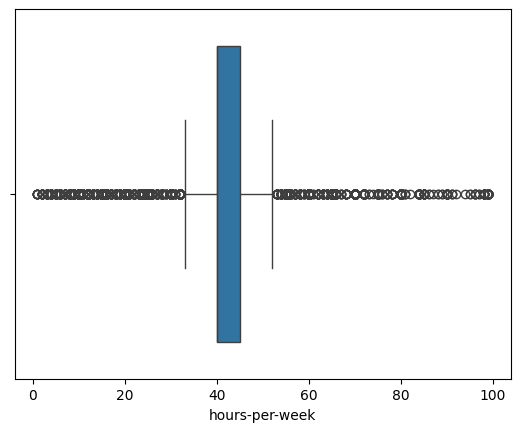

In [33]:
sns.boxplot(x=df["hours-per-week"])

In [35]:
Q3 = df["hours-per-week"].quantile(0.75)
Q3

np.float64(45.0)

In [38]:
Q1 = df["hours-per-week"].quantile(0.25)
Q1

np.float64(40.0)

#   6. Estadistica Descriptiva

In [41]:
df.describe()

,Unnamed: 0,age,education-num,capital-gain,capital-loss,hours-per-week
count,30161.000000,30161.000000,30161.000000,30161.000000,30161.000000,30161.000000
mean,16287.643148,38.437419,10.121415,1092.044064,88.375419,40.931269
std,9383.088720,13.134615,2.549974,7406.466611,404.304753,11.980182
min,0.000000,17.000000,1.000000,0.000000,0.000000,1.000000
25%,8179.000000,28.000000,9.000000,0.000000,0.000000,40.000000
50%,16286.000000,37.000000,10.000000,0.000000,0.000000,40.000000
75%,24402.000000,47.000000,13.000000,0.000000,0.000000,45.000000
max,32560.000000,90.000000,16.000000,99999.000000,4356.000000,99.000000


In [42]:
df.describe(include="all")

,Unnamed: 0,age,workclass,education,education-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
count,30161.000000,30161.000000,30161,30161,30161.000000,30161,30161,30161,30161,30161,30161.000000,30161.000000,30161.000000,30161,30161
unique,NaN,NaN,7,16,NaN,7,14,6,5,2,NaN,NaN,NaN,41,2
top,NaN,NaN,Private,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,NaN,22285,9840,NaN,14064,4038,12462,25933,20379,NaN,NaN,NaN,27503,22653
mean,16287.643148,38.437419,NaN,NaN,10.121415,NaN,NaN,NaN,NaN,NaN,1092.044064,88.375419,40.931269,NaN,NaN
std,9383.088720,13.134615,NaN,NaN,2.549974,NaN,NaN,NaN,NaN,NaN,7406.466611,404.304753,11.980182,NaN,NaN
min,0.000000,17.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,8179.000000,28.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,16286.000000,37.000000,NaN,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,24402.000000,47.000000,NaN,NaN,13.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN


In [43]:
df["age"].mean()

np.float64(38.43741918371407)

#   7. Desbalance de Clases

In [44]:
df["income"].unique()

array([' <=50K', ' >50K'], dtype=object)

In [46]:
df["income"].value_counts()

,count
income,
<=50K,22653
>50K,7508


In [49]:
df["income"].value_counts(normalize=True)*100

,proportion
income,
<=50K,75.106926
>50K,24.893074


<Axes: xlabel='income', ylabel='count'>

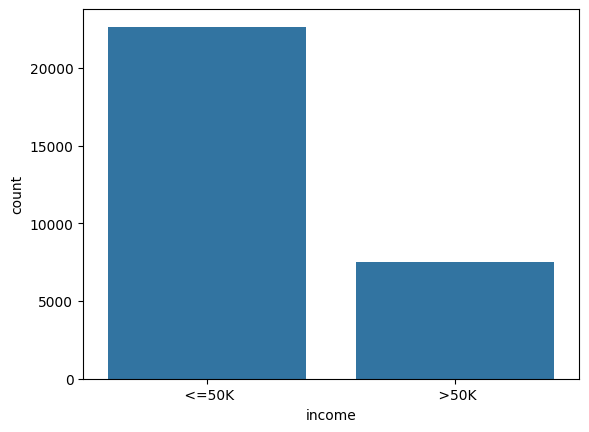

In [51]:
sns.countplot(data=df, x="income")

<Axes: xlabel='income'>

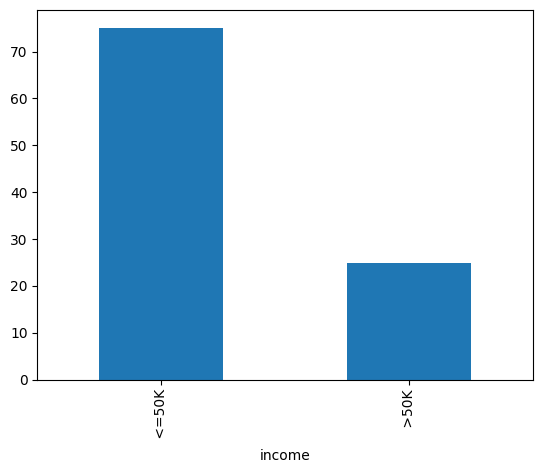

In [52]:
(df["income"].value_counts(normalize=True) * 100).plot(kind="bar")

#   8. Análisis Univariado/Distribuciones

In [54]:
df.select_dtypes(include="number").columns

Index(['Unnamed: 0', 'age', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')

<Axes: xlabel='education-num', ylabel='Count'>

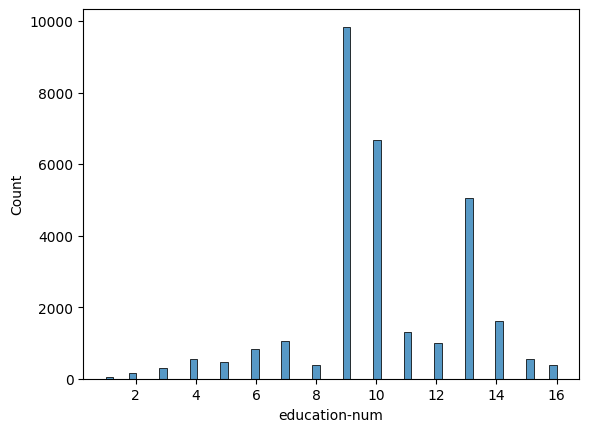

In [56]:
sns.histplot(df["education-num"])

In [57]:
df["age"].skew()

np.float64(0.5303165042654331)

<Axes: xlabel='age', ylabel='Count'>

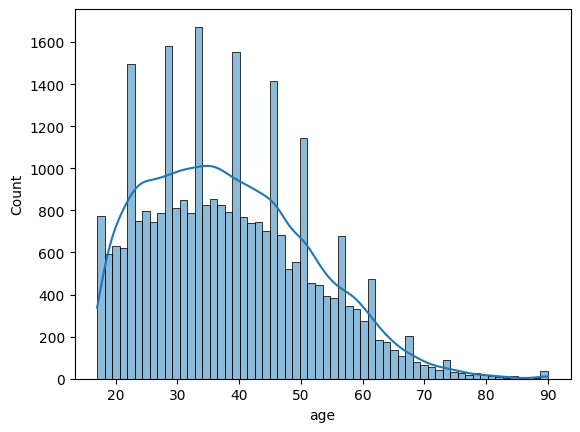

In [59]:
sns.histplot(df["age"], kde=True)

In [60]:
df["age"].kurt()

np.float64(-0.14450813842955368)

In [61]:
df["hours-per-week"].kurt()

np.float64(3.167682631106674)

<Axes: xlabel='hours-per-week', ylabel='Count'>

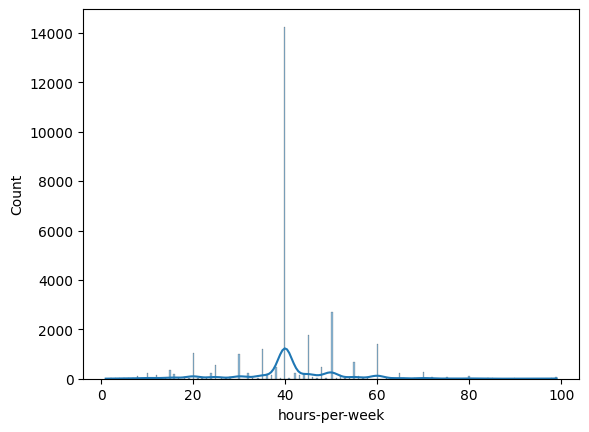

In [64]:
sns.histplot(df["hours-per-week"], kde=True)

<Axes: xlabel='age'>

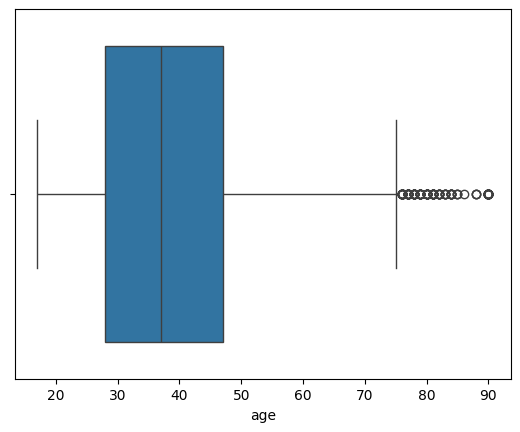

In [66]:
sns.boxplot(x=df["age"])

<Axes: xlabel='age', ylabel='count'>

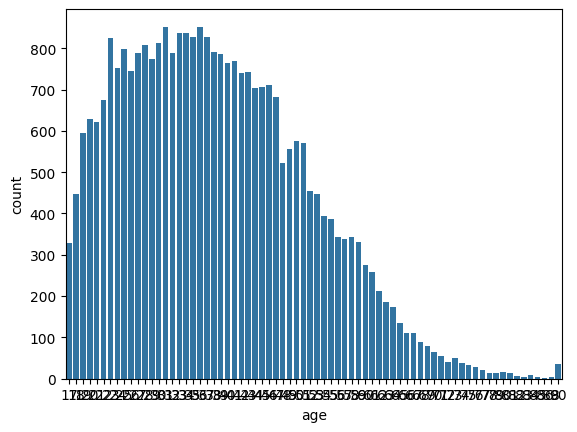

In [67]:
sns.countplot(data=df, x="inco")

#   9. Análisis Bivariado

#   10. Análisis MultiVariado